# Around and within stressed oligodendrocytes: neighbourhoods and order of events

Follows `02` / `03`. Two questions, both answered **within tissue sections** (so slide, section plane and time of
sacrifice cannot create the signal) and with **prespecified gene sets** (`utils/gene_sets.py`):

1. **Neighbourhoods** (`utils/neighbourhood.py`): are microglia, astrocytes and endothelial cells next to stressed
   OLs more activated? For each such cell, the ISR score of all OLs within 50 um is averaged ("local OL stress");
   its own readout (DAM, homeostatic, reactive-astrocyte, endothelial activation, MHC-I, interferon) is correlated
   with that local stress after centring both within (section, region). Controls are the null.
2. **Order of events** (`utils/ol_staging.py`): in responding tissue, do OLs turn on the ISR before they lose myelin
   genes? ISR and myelin scores per OL, smoothed over 15 neighbouring OLs, as percentiles of same-slide, same-region
   control OLs; OLs classed ISR-high (> 90th) and myelin-low (< 10th).

Input: `results/cell_table/cell_gene_scores.csv.gz` (`scripts/export_cell_gene_scores.py`, office Mac).

In [1]:
import sys, itertools
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import neighbourhood as nbh, ol_staging as st
from utils.gene_sets import GENE_SETS, NEIGHBOUR_READOUTS

OUT = REPO / "results" / "neighbourhood_staging"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]
cs = pd.read_csv(REPO / "results" / "cell_table" / "cell_gene_scores.csv.gz", index_col=0)
xy = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz", index_col=0, usecols=["cell_id", "x_centroid", "y_centroid"])
cs = cs.join(xy); cs = cs[cs.region != "Unknown"]

INK, INK2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df

def perm_p(values: pd.Series, a, b):
    # exact one-sided permutation p for mean(a) - mean(b) over all relabellings of a + b
    v = values.loc[list(a) + list(b)].to_numpy(); na = len(a)
    obs = v[:na].mean() - v[na:].mean()
    null = [v[list(c)].mean() - np.delete(v, list(c)).mean() for c in itertools.combinations(range(len(v)), na)]
    return float(np.mean(np.array(null) >= obs - 1e-12)), obs, len(null)

## 1. Neighbourhoods: coupling of neighbour activation to local OL stress

In [2]:
coup_all = []
for rad in (30, 50, 100):
    loc = nbh.local_ol_stress(cs, list(NEIGHBOUR_READOUTS), radius=rad)
    c = nbh.coupling(loc, NEIGHBOUR_READOUTS, grp).assign(radius_um=rad)
    coup_all.append(c)
    if rad == 50:
        loc50 = loc
coup = pd.concat(coup_all)
save_table(coup.round(4), "coupling_per_section", index=False)

rows = []
for (ct, ro, rad), d in coup.groupby(["cell_type", "readout", "radius_um"]):
    r = d.set_index("sample_id")["r"]
    if not set(resp) <= set(r.index) or not set(ctrl) <= set(r.index):
        continue
    p, diff, n = perm_p(r, resp, ctrl) if ro != "HOMEOSTATIC" else perm_p(-r, resp, ctrl)
    rows.append({"cell_type": ct, "readout": ro, "radius_um": rad,
                 "r_control": r.loc[ctrl].mean(), "r_non_responder": r.reindex(sections.index[grp == "non-responder"]).mean(),
                 "r_responder": r.loc[resp].mean(), "perm_p_resp_vs_ctrl": p, "n_perm": n,
                 "direction_tested": "lower in responders" if ro == "HOMEOSTATIC" else "higher in responders"})
summ = save_table(pd.DataFrame(rows).round(4), "coupling_summary", index=False)
display(summ[summ.radius_um == 50])
display(summ.pivot_table(index=["cell_type", "readout"], columns="radius_um", values="perm_p_resp_vs_ctrl"))

,cell_type,readout,radius_um,r_control,r_non_responder,r_responder,perm_p_resp_vs_ctrl,n_perm,direction_tested
1,Astrocytes,ASTRO_REACTIVE,50,-0.0390,-0.0074,0.0560,0.0119,84,higher in responders
4,Astrocytes,IFN,50,-0.0052,0.0027,0.0039,0.1429,84,higher in responders
7,Astrocytes,MHC1,50,-0.0063,0.0119,0.0202,0.0714,84,higher in responders
10,Endothelial Cells,ENDO_ACTIVATION,50,-0.0022,0.0074,-0.0146,0.8690,84,higher in responders
13,Endothelial Cells,IFN,50,0.0045,0.0132,0.0043,0.5000,84,higher in responders
16,Endothelial Cells,MHC1,50,0.0019,0.0052,0.0056,0.4167,84,higher in responders
19,Microglia,DAM,50,0.0336,0.0186,0.0817,0.0476,84,higher in responders
22,Microglia,HOMEOSTATIC,50,-0.0189,0.0248,-0.0484,0.1310,84,lower in responders
25,Microglia,IFN,50,0.0114,-0.0164,-0.0253,0.9048,84,higher in responders
28,Microglia,MHC1,50,0.0014,0.0012,0.0311,0.0119,84,higher in responders


radius_um                             30      50      100
cell_type         readout                                
Astrocytes        ASTRO_REACTIVE   0.0119  0.0119  0.0119
                  IFN              0.2381  0.1429  0.0476
                  MHC1             0.1548  0.0714  0.0238
Endothelial Cells ENDO_ACTIVATION  0.5833  0.8690  0.8095
                  IFN              0.3929  0.5000  0.7738
                  MHC1             0.1548  0.4167  0.7738
Microglia         DAM              0.0833  0.0476  0.0119
                  HOMEOSTATIC      0.2976  0.1310  0.0238
                  IFN              0.3690  0.9048  0.7262
                  MHC1             0.0714  0.0119  0.0119

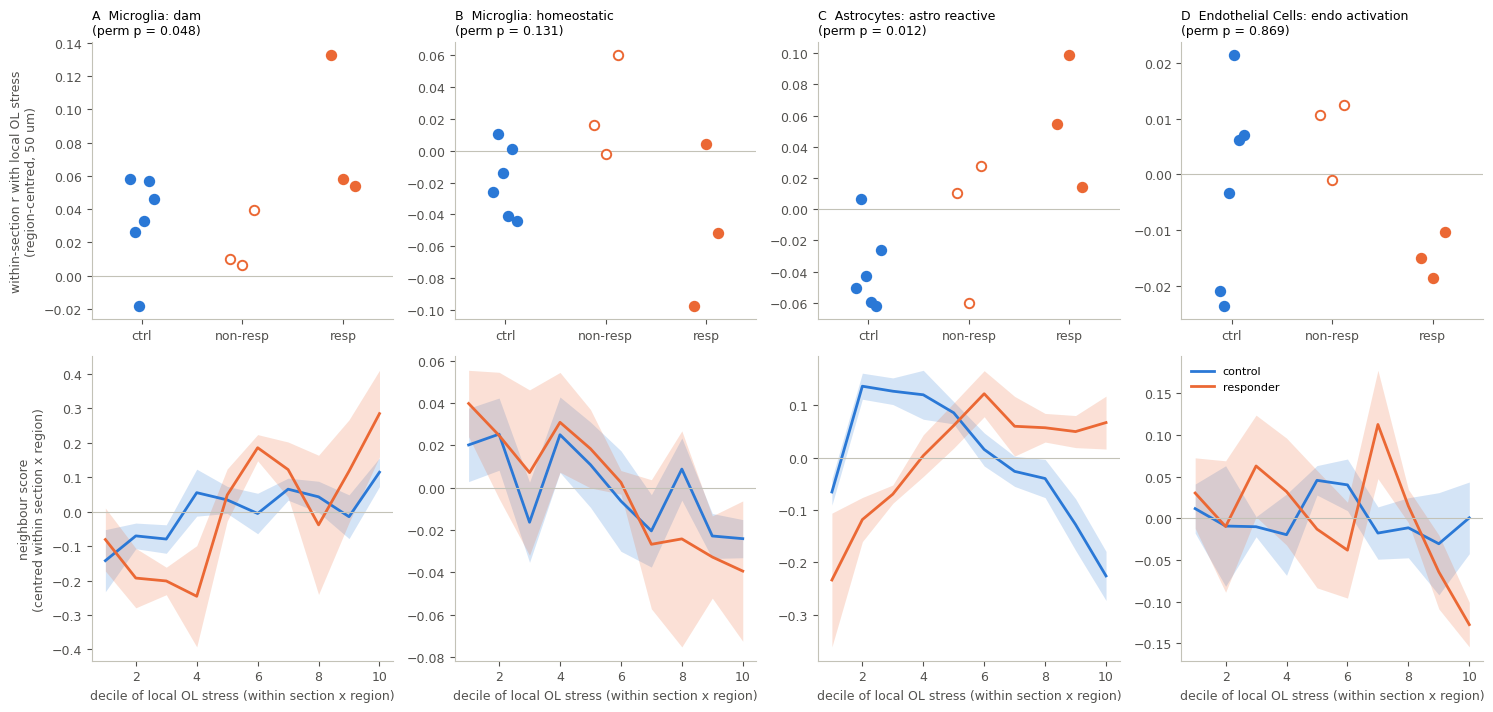

In [3]:
show = [("Microglia", "DAM"), ("Microglia", "HOMEOSTATIC"), ("Astrocytes", "ASTRO_REACTIVE"), ("Endothelial Cells", "ENDO_ACTIVATION")]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), gridspec_kw={"height_ratios": [1, 1.1]})
c50 = coup[coup.radius_um == 50]
for j, (ct, ro) in enumerate(show):
    ax = axes[0, j]
    d = c50[(c50.cell_type == ct) & (c50.readout == ro)]
    for gi, g in enumerate(GROUP_ORDER):
        v = d[d.group == g]["r"].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    ax.axhline(0, color=AXIS, lw=0.8)
    p = summ[(summ.cell_type == ct) & (summ.readout == ro) & (summ.radius_um == 50)]["perm_p_resp_vs_ctrl"]
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5)
    ax.set_title(f"{'ABCD'[j]}  {ct}: {ro.replace('_', ' ').lower()}\n(perm p = {p.iloc[0]:.3f})" if len(p) else f"{ct}: {ro}", fontsize=9)
    if j == 0: ax.set_ylabel("within-section r with local OL stress\n(region-centred, 50 um)")
    ax = axes[1, j]
    b = nbh.binned_response(loc50, ro, ct, grp)
    for g in ["control", "responder"]:
        m = b[b.group == g].groupby("bin")["readout_c"].agg(["mean", "sem"])
        col = BLUE if g == "control" else ORANGE
        ax.plot(m.index + 1, m["mean"], color=col, lw=2, label=g)
        ax.fill_between(m.index + 1, m["mean"] - m["sem"], m["mean"] + m["sem"], color=col, alpha=0.2, lw=0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xlabel("decile of local OL stress (within section x region)")
    if j == 0: ax.set_ylabel("neighbour score\n(centred within section x region)")
    if j == 3: ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "N1_neighbour_coupling")

**Reading N1.** Top: one dot per mouse. Bottom: the neighbour's score across deciles of local OL stress (mean +- SEM
over mice). Microglia next to stressed OLs are more DAM-like and less homeostatic, and astrocytes more reactive,
only in responders; endothelial cells show no coupling. Correlations are small because single-cell scores are
noisy; the permutation test compares the 3 responders with the 6 controls (84 relabellings, floor p = 0.012).

## 2. Order of events: ISR before myelin loss?

In [4]:
ols = cs[cs.cell_type == "Oligodendrocytes"].copy()
ols["slide_region"] = ols.sample_id.map(sections["age"]).astype(str) + "|" + ols.region
ols = st.smooth_scores(ols, ["ISR", "MYELIN"], k=15)
ols["ISR_pct"] = st.control_percentile(ols, "ISR_smooth", ctrl, by="slide_region")
ols["MYELIN_pct"] = st.control_percentile(ols, "MYELIN_smooth", ctrl, by="slide_region")
states = st.state_table(ols).join(sections[["age", "group"]])
save_table(states.round(4), "ol_isr_myelin_states")
display(states.sort_values(["group", "frac_isr_high"]).round(3))
p1, d1, n1 = perm_p(states["p_myelin_low_given_isr_high"], resp, ctrl)
p2, d2, n2 = perm_p(states["isr_high_myelin_normal"], resp, ctrl)
print(f"P(myelin-low | ISR-high): responders - controls = {d1:.2f}, perm p = {p1:.3f}")
print(f"ISR-high with normal myelin: responders - controls = {d2:.3f}, perm p = {p2:.3f}")
bins = st.myelin_by_isr_bin(ols); bins["group"] = bins.sample_id.map(grp)
save_table(bins.round(3), "myelin_by_isr_bin", index=False)

,n_OLs,frac_isr_high,frac_myelin_low,isr_high_myelin_normal,isr_high_myelin_low,isr_normal_myelin_low,p_myelin_low_given_isr_high,p_isr_high_given_myelin_low,age,group
sample_id,,,,,,,,,,
RB4620,13965,0.066,0.043,0.057,0.008,0.035,0.129,0.195,21,control
RB4350,12487,0.074,0.149,0.055,0.019,0.130,0.253,0.126,60,control
RB4282,14198,0.094,0.046,0.086,0.009,0.037,0.093,0.190,60,control
RB4658,10884,0.100,0.110,0.075,0.025,0.085,0.250,0.227,21,control
RB4498,13303,0.131,0.111,0.111,0.020,0.091,0.153,0.181,60,control
RB4676,14204,0.134,0.147,0.101,0.033,0.114,0.249,0.227,21,control
RB4403,23485,0.108,0.272,0.071,0.037,0.235,0.343,0.136,60,non-responder
RB4653,11774,0.121,0.176,0.081,0.040,0.137,0.329,0.226,21,non-responder
RB4630,11547,0.133,0.146,0.105,0.028,0.118,0.210,0.192,21,non-responder


P(myelin-low | ISR-high): responders - controls = 0.49, perm p = 0.012
ISR-high with normal myelin: responders - controls = 0.054, perm p = 0.083


,sample_id,isr_bin,mean,size,group
0,RB4282,"[0.0, 50.0)",65.581,7091,control
1,RB4282,"[50.0, 75.0)",58.441,3563,control
2,RB4282,"[75.0, 90.0)",55.756,2204,control
3,RB4282,"[90.0, 95.0)",55.325,719,control
4,RB4282,"[95.0, 99.0)",56.613,514,control
...,...,...,...,...,...
67,RB4676,"[50.0, 75.0)",38.991,3748,control
68,RB4676,"[75.0, 90.0)",35.387,2548,control
69,RB4676,"[90.0, 95.0)",32.910,968,control
70,RB4676,"[95.0, 99.0)",28.658,725,control


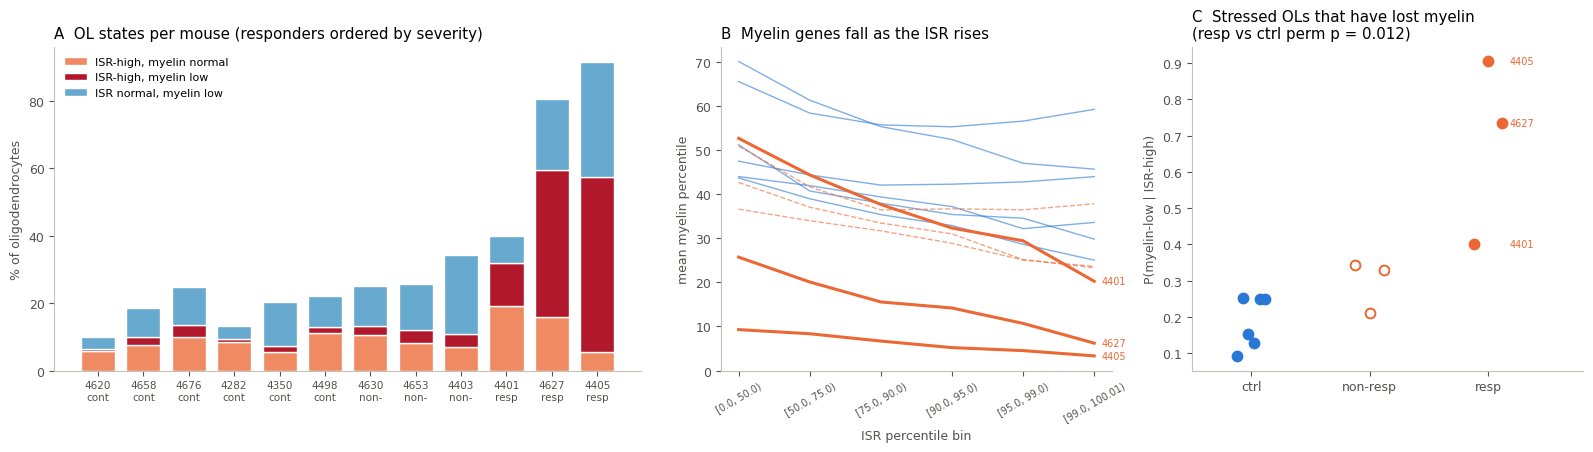

In [5]:
order = list(ctrl) + list(sections.index[grp == "non-responder"]) + ["RB4401", "RB4627", "RB4405"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.5, 1, 1]})
ax = axes[0]
parts = [("isr_high_myelin_normal", "ISR-high, myelin normal", "#ef8a62"), ("isr_high_myelin_low", "ISR-high, myelin low", "#b2182b"),
         ("isr_normal_myelin_low", "ISR normal, myelin low", "#67a9cf")]
bottom = np.zeros(len(order))
for col, lab, colr in parts:
    v = states.loc[order, col].to_numpy() * 100
    ax.bar(range(len(order)), v, bottom=bottom, color=colr, label=lab, width=0.75, edgecolor="white", linewidth=1)
    bottom += v
ax.set_xticks(range(len(order)), [f"{s[2:]}\n{grp[s][:4]}" for s in order], fontsize=7.5)
ax.set_ylabel("% of oligodendrocytes"); ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.set_title("A  OL states per mouse (responders ordered by severity)")
ax = axes[1]
for s in order:
    b = bins[bins.sample_id == s]
    g = grp[s]; col = BLUE if g == "control" else ORANGE
    ax.plot(range(len(b)), b["mean"], color=col, lw=2.2 if g == "responder" else 1, ls="--" if g == "non-responder" else "-",
            alpha=1 if g == "responder" else 0.6)
    if g == "responder": ax.text(len(b) - 0.9, b["mean"].iloc[-1], s[2:], fontsize=7, color=ORANGE, va="center")
ax.set_xticks(range(len(b)), [str(i) for i in b["isr_bin"]], rotation=30, fontsize=7)
ax.set_xlabel("ISR percentile bin"); ax.set_ylabel("mean myelin percentile")
ax.set_title("B  Myelin genes fall as the ISR rises")
ax = axes[2]
for gi, g in enumerate(GROUP_ORDER):
    v = states[states.group == g]["p_myelin_low_given_isr_high"]
    ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=50, linewidth=1.4, zorder=3, **STYLE[g])
    if g == "responder":
        for s, val in v.items(): ax.text(gi + 0.18, val, s[2:], fontsize=7, color=ORANGE, va="center")
ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.8)
ax.set_ylabel("P(myelin-low | ISR-high)")
ax.set_title(f"C  Stressed OLs that have lost myelin\n(resp vs ctrl perm p = {p1:.3f})")
fig.tight_layout()
save(fig, "N2_isr_myelin_staging")

**Reading N2.** In the mildest responder (RB4401) a third of OLs are ISR-high and most of them still have normal
myelin genes; with increasing severity (RB4627, RB4405) a growing share of stressed OLs has also lost myelin, and in
the most severe animal myelin loss extends beyond the ISR-high cells. Myelin genes decline steadily with ISR level in
responders (B). This cross-sectional pattern is consistent with stress preceding myelin loss, but it is not a time
course. Caveat: non-responder RB4403 shows somewhat more myelin-low OLs than controls, likely its over-segmentation
(split cells carry fewer transcripts).